In [ ]:
SECT-4451 — Lecture 2 Practical
Data Exploration & Foundational Math
Objective: Explore and clean the provided student-performance dataset, summarize and visualize the data, examine correlation, calculate a vector dot product, and standardize selected features.
This notebook uses the dataset-generation code provided in the assignment. All results and plots are generated in the notebook.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

n = 100
study_hours = np.random.normal(5, 2, n)
attendance = np.random.normal(85, 10, n)
previous_mark = np.random.normal(70, 15, n)
final_score = (
    (0.5 * study_hours)
    + (0.3 * attendance)
    + (0.2 * previous_mark)
    + np.random.normal(0, 5, n)
)

df = pd.DataFrame({
    "study_hours": study_hours,
    "attendance": attendance,
    "previous_mark": previous_mark,
    "final_score": final_score
})

# Dirty records 
df.loc[0:5, "study_hours"] = np.nan
df.loc[99, "study_hours"] = 50
df.loc[98, "attendance"] = -10

df.head(10)

,study_hours,attendance,previous_mark,final_score
0,NaN,70.846293,75.366810,35.178989
1,NaN,80.793547,78.411768,39.481248
2,NaN,81.572855,86.245769,48.605167
3,NaN,76.977227,85.807031,47.329456
4,NaN,83.387143,49.334959,37.044473
5,NaN,89.040509,55.932624,40.751177
6,8.158426,103.861859,77.725529,57.171201
7,6.534869,86.745778,77.706789,41.874669
8,4.061051,87.575504,77.725715,46.583807
9,6.085120,84.255541,127.790972,52.866454


In [ ]:
Part A — Inspect and Clean
A1. Identify and handle the outlier
The record at index 99 has study_hours = 50, which is unusually high compared with the normal distribution used to generate study hours (mean 5, standard deviation 2). I will cap this value at the upper Tukey fence (Q3 + 1.5 × IQR), a common outlier-handling method. Capping keeps the student's record while reducing the extreme value's influence.
The first six study_hours values are missing, and the attendance value at index 98 is -10, which is impossible for a percentage. I will impute missing study hours with the median and replace the impossible attendance value with the median of valid attendance values. Medians are robust to outliers.

In [15]:
# Inspect the dirty records
print("Missing study_hours:", df["study_hours"].isna().sum())
print("Record with 50 study hours:\n", df.loc[df["study_hours"] == 50])
print("Record with impossible attendance:\n", df.loc[df["attendance"] < 0])

# Work on a cleaned copy, preserving the original df
clean_df = df.copy()

# Calculate the upper Tukey fence using the non-missing study-hours values
q1 = clean_df["study_hours"].quantile(0.25)
q3 = clean_df["study_hours"].quantile(0.75)
iqr = q3 - q1
upper_fence = q3 + 1.5 * iqr

# Cap study_hours above the upper fence
clean_df["study_hours"] = clean_df["study_hours"].clip(upper=upper_fence)

# Impute missing study_hours with the median
study_median = clean_df["study_hours"].median()
clean_df["study_hours"] = clean_df["study_hours"].fillna(study_median)

# Replace impossible negative attendance with the median of valid attendance values
valid_attendance_median = clean_df.loc[clean_df["attendance"] >= 0, "attendance"].median()
clean_df.loc[clean_df["attendance"] < 0, "attendance"] = valid_attendance_median

print(f"Q1: {q1:.2f}")
print(f"Q3: {q3:.2f}")
print(f"IQR: {iqr:.2f}")
print(f"Upper fence used for capping: {upper_fence:.2f}")
print(f"Study-hours median used for imputation: {study_median:.2f}")
print(f"Valid-attendance median used for correction: {valid_attendance_median:.2f}")
print("\nCleaned records at the affected indices:")
clean_df.loc[[0, 1, 2, 3, 4, 5, 98, 99]]



Missing study_hours: 6
Record with 50 study hours:
     study_hours  attendance  previous_mark  final_score
99         50.0   73.570297      79.444433     46.41447
Record with impossible attendance:
     study_hours  attendance  previous_mark  final_score
98     5.010227       -10.0      82.192932    44.045627
Q1: 3.73
Q3: 5.74
IQR: 2.01
Upper fence used for capping: 8.76
Study-hours median used for imputation: 4.81
Valid-attendance median used for correction: 86.00

Cleaned records at the affected indices:


,study_hours,attendance,previous_mark,final_score
0,4.812342,70.846293,75.366810,35.178989
1,4.812342,80.793547,78.411768,39.481248
2,4.812342,81.572855,86.245769,48.605167
3,4.812342,76.977227,85.807031,47.329456
4,4.812342,83.387143,49.334959,37.044473
5,4.812342,89.040509,55.932624,40.751177
98,5.010227,85.996514,82.192932,44.045627
99,8.763712,73.570297,79.444433,46.414470


In [ ]:
A2. Feature matrix shape, numerical columns, and target
The original dataset has 100 rows and 4 columns, so its feature table has shape (100, 4). For modeling, the feature matrix X excludes the target column and has shape (100, 3). The numerical predictor columns are study_hours, attendance, and previous_mark. The target variable is final_score.
The cleaned dataset still has 100 rows and 4 columns; cleaning changes values but does not remove rows.

In [18]:
print("Original dataset shape:", df.shape)
X = clean_df[["study_hours", "attendance", "previous_mark"]]
y = clean_df["final_score"]
print("Feature matrix X shape:", X.shape)
print("Target y shape:", y.shape)
print("Numerical columns:", clean_df.select_dtypes(include=np.number).columns.tolist())
print("Target variable: final_score")

Original dataset shape: (100, 4)
Feature matrix X shape: (100, 3)
Target y shape: (100,)
Numerical columns: ['study_hours', 'attendance', 'previous_mark', 'final_score']
Target variable: final_score


In [ ]:
Part B — Summarize
B1. Mean, median, and standard deviation for all columns
The summary below uses the cleaned dataset. Pandas' standard deviation uses the sample standard deviation (ddof=1) by default.

In [19]:
summary = pd.DataFrame({
    "mean": clean_df.mean(numeric_only=True),
    "median": clean_df.median(numeric_only=True),
    "standard_deviation": clean_df.std(numeric_only=True)
})
summary.round(2)

,mean,median,standard_deviation
study_hours,4.78,4.81,1.82
attendance,85.23,86.00,9.54
previous_mark,70.97,71.47,16.26
final_score,42.69,42.76,6.09


In [ ]:
B2. Three observations 
1. Study hours: The study-hours values are much less spread out after the extreme value is capped and missing values are filled with the median. This makes the summary less affected by the unusually large 50-hour entry.
2. Attendance: Attendance values are centered around the typical attendance rate after the impossible -10 value is corrected. A negative attendance percentage is not realistic.
3. Final score: Final scores vary from student to student. The standard deviation in the summary table describes the typical spread of scores around their mean.
Use the printed summary table to quote the exact mean, median, and standard deviation values if your instructor expects numerical evidence.

In [ ]:
Part C — Visualize
C1. Histogram of final_score
A histogram groups final scores into bins and shows how frequently scores occur.

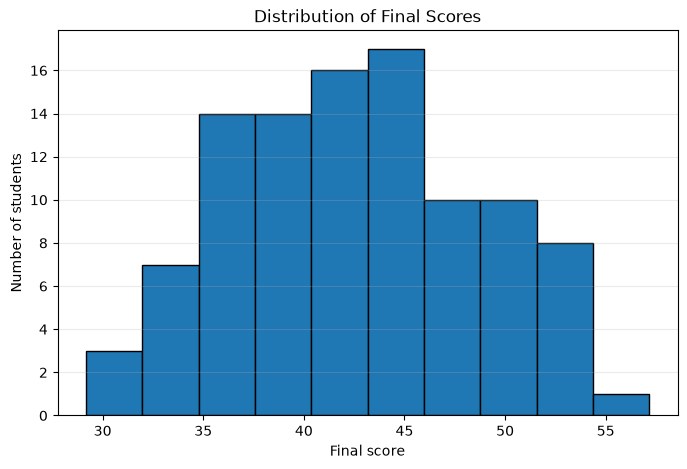

In [20]:
plt.figure(figsize=(8, 5))
plt.hist(clean_df["final_score"], bins=10, edgecolor="black")
plt.title("Distribution of Final Scores")
plt.xlabel("Final score")
plt.ylabel("Number of students")
plt.grid(axis="y", alpha=0.25)
plt.show()

In [ ]:
C2. Scatter plot of study_hours versus final_score
Each point represents one student. Study hours are on the horizontal axis and final score is on the vertical axis.

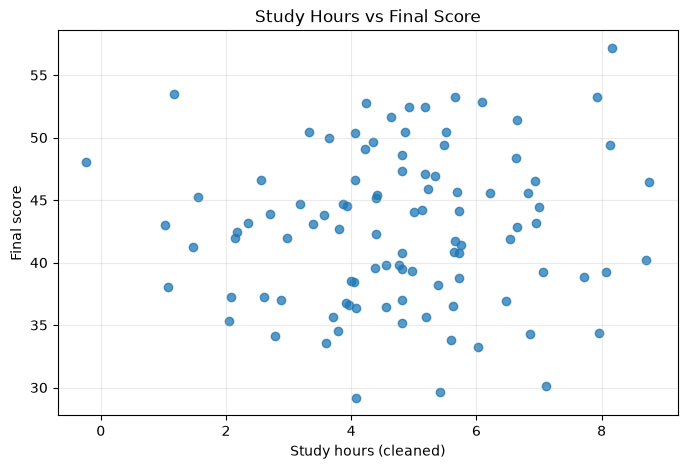

In [21]:
plt.figure(figsize=(8, 5))
plt.scatter(clean_df["study_hours"], clean_df["final_score"], alpha=0.75)
plt.title("Study Hours vs Final Score")
plt.xlabel("Study hours (cleaned)")
plt.ylabel("Final score")
plt.grid(alpha=0.25)
plt.show()

In [ ]:
Trend description: The points are expected to show a generally positive but not perfectly straight relationship: students with more study hours tend to have somewhat higher scores, but there is variation. Study hours are only one part of the score formula, and random noise also affects scores.

In [ ]:
Part D — Correlation and Causality
D1. Pearson correlation between study_hours and final_score
Pearson's correlation coefficient ranges from -1 to +1. Positive values indicate that higher study hours tend to be associated with higher final scores; values near zero indicate a weak linear association.

In [22]:
correlation = clean_df["study_hours"].corr(clean_df["final_score"], method="pearson")
print(f"Pearson correlation coefficient: {correlation:.4f}")

Pearson correlation coefficient: 0.0619


In [ ]:
D2. Does correlation guarantee a specific score? What could be a confounding variable?
No. Correlation does not guarantee that a student who studies 10 hours will earn a particular score. It describes an overall linear association across the dataset, not an exact prediction for an individual. Students can have different prior knowledge, sleep quality, study methods, health, exam difficulty, or access to learning resources.
A possible lurking or confounding variable is previous knowledge, represented partly by previous_mark. Students with stronger prior knowledge may both find studying easier and achieve higher scores. Attendance can also affect performance. These variables help explain why study hours alone cannot determine a student's score.

In [ ]:
Part E — Vectors and Dot Product
E1–E3. Select one student's predictor vector and calculate the weighted sum
The vector x contains one student's three input features, excluding the target final_score. The weight vector is [0.5, 0.2, 0.4] and the bias is 5. The calculation is y = w ·x + b.

In [23]:
# Select the first cleaned student row's features, excluding final_score
x = clean_df.loc[0, ["study_hours", "attendance", "previous_mark"]].to_numpy(dtype=float)
w = np.array([0.5, 0.2, 0.4])
b = 5

weighted_sum = np.dot(w, x) + b

print("Selected feature names:", ["study_hours", "attendance", "previous_mark"])
print("Student feature vector x:", x)
print("Weight vector w:", w)
print("Bias b:", b)
print(f"y = w · x + b = {weighted_sum:.4f}")

Selected feature names: ['study_hours', 'attendance', 'previous_mark']
Student feature vector x: [ 4.8123416  70.84629258 75.36681041]
Weight vector w: [0.5 0.2 0.4]
Bias b: 5
y = w · x + b = 51.7222


In [ ]:
E4. What do the weights and bias represent?
The weights specify how much each feature contributes to the weighted sum: 0.5 for study hours, 0.2 for attendance, and 0.4 for previous mark. A larger weight means a larger contribution per one-unit change in that feature, assuming the other features stay the same.
The bias (b = 5) is a constant added to the weighted sum. It lets the prediction shift up or down instead of forcing the result to be zero when all features are zero. These are the weights supplied by the exercise; they are not trained from the data, so this calculation is an illustrative weighted prediction rather than a fitted model.

In [ ]:
Part F — Scaling
F1. Standardize study_hours and previous_mark
Standardization transforms each value using z = (x - mean) / standard deviation. The standardized columns have mean approximately 0 and standard deviation approximately 1. Here, the mean and sample standard deviation are calculated from the cleaned data.

In [24]:
scaled_df = clean_df.copy()

for column in ["study_hours", "previous_mark"]:
    mean_value = clean_df[column].mean()
    std_value = clean_df[column].std(ddof=1)
    scaled_df[column + "_standardized"] = (clean_df[column] - mean_value) / std_value

print("Original ranges:")
print(clean_df[["study_hours", "previous_mark"]].agg(["min", "max"]).round(2))
print("\nStandardized columns (first 5 rows):")
print(scaled_df[["study_hours_standardized", "previous_mark_standardized"]].head().round(3))
print("\nCheck standardized means and sample standard deviations:")
print(scaled_df[["study_hours_standardized", "previous_mark_standardized"]].agg(["mean", "std"]).round(3))

Original ranges:
     study_hours  previous_mark
min        -0.24          21.38
max         8.76         127.79

Standardized columns (first 5 rows):
   study_hours_standardized  previous_mark_standardized
0                     0.017                       0.270
1                     0.017                       0.457
2                     0.017                       0.939
3                     0.017                       0.912
4                     0.017                      -1.330

Check standardized means and sample standard deviations:
      study_hours_standardized  previous_mark_standardized
mean                       0.0                         0.0
std                        1.0                         1.0


In [ ]:
F2. Why does scaling matter for K-Nearest Neighbors (KNN)?
KNN compares observations using a distance measure such as Euclidean distance. In the original data, previous_mark typically spans a much wider numerical range than study_hours (marks are measured in tens, while study hours are usually only a few hours). Without scaling, differences in previous marks can dominate the distance calculation, even if study hours are also useful.
Standardization puts both features on comparable scales, so neither feature dominates only because of its units or numerical range. It does not make the features equally important in every sense; it simply makes their scales more comparable.

In [ ]:
Conclusion
This practical demonstrated data cleaning, descriptive statistics, visual exploration, Pearson correlation, a NumPy dot product, and feature standardization. Cleaning invalid and missing values before analysis helps make the results more reliable, while plots and correlation describe patterns without proving cause and effect.